# **scamSHILD**







Import libraries

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


 Dataset upload aur load

In [6]:

import pandas as pd

df = pd.read_csv(
    "../dataset/spam.csv",
    encoding="latin-1"
)

print(df.head())
print("\nColumns:", df.columns.tolist())
print("\nDataset shape:", df.shape)


     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Dataset shape: (5572, 5)


In [7]:

df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

df = df[["label", "message"]].copy()

print(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64


 Dataset explore

In [8]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print(
    (df["label"].value_counts(normalize=True) * 100).round(2)
)

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

Duplicate rows: 403


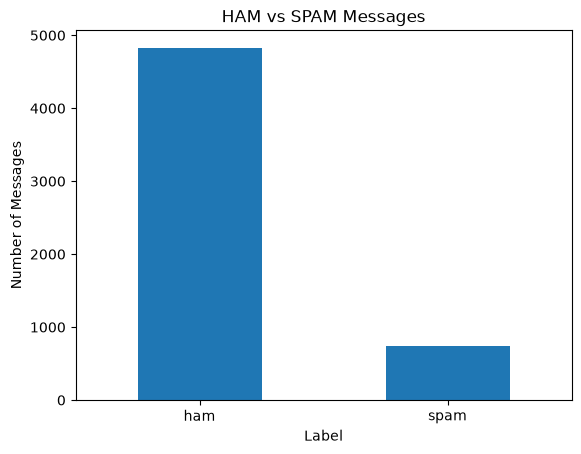

In [9]:

df["label"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("HAM vs SPAM Messages")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.show()


 Data clean


In [10]:

df = df.dropna(subset=["label", "message"]).copy()

# Standardize labels
df["label"] = df["label"].astype(str).str.strip().str.lower()

# Standardize message text
df["message"] = df["message"].astype(str).str.strip()

# Keep only valid labels and non-empty messages
df = df[
    df["label"].isin(["ham", "spam"]) &
    df["message"].ne("")
].copy()

# Normalize text for duplicate detection
def normalize_message(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["normalized_message"] = df["message"].apply(normalize_message)

# Remove exact duplicate label-message rows
df = df.drop_duplicates(subset=["label", "normalized_message"])

# Remove messages that have conflicting labels
label_counts = df.groupby("normalized_message")["label"].nunique()
conflicting_messages = label_counts[label_counts > 1].index

df = df[
    ~df["normalized_message"].isin(conflicting_messages)
].copy()

df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nFinal label distribution:")
print(df["label"].value_counts())

display(df.head())


Cleaned dataset shape: (5157, 3)

Final label distribution:
label
ham     4515
spam     642
Name: count, dtype: int64


,label,message,normalized_message
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."



Training

In [11]:

X = df["normalized_message"]
y = df["label"]

# First: 70% training, 30% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=2026,
    stratify=y
)

# Split remaining data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=2026,
    stratify=y_remaining
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())


Training samples: 3609
Validation samples: 774
Test samples: 774

Training labels:
label
ham     3160
spam     449
Name: count, dtype: int64

Validation labels:
label
ham     678
spam     96
Name: count, dtype: int64

Test labels:
label
ham     677
spam     97
Name: count, dtype: int64


In [12]:

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

# Learn vocabulary and IDF values from training messages only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the same learned transformation to other sets
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

print("\nNumber of learned words/features:", len(tfidf.vocabulary_))


Training TF-IDF shape: (3609, 38114)
Validation TF-IDF shape: (774, 38114)
Test TF-IDF shape: (774, 38114)

Number of learned words/features: 38114


In [13]:

C_values = [1, 2, 5, 10]
results = []

for c in C_values:
    candidate_model = LogisticRegression(
        C=c,
        class_weight="balanced",
        max_iter=1000,
        random_state=2026
    )

    candidate_model.fit(X_train_tfidf, y_train)

    val_predictions = candidate_model.predict(X_val_tfidf)

    spam_precision = precision_score(
        y_val, val_predictions, pos_label="spam", zero_division=0
    )
    spam_recall = recall_score(
        y_val, val_predictions, pos_label="spam", zero_division=0
    )
    spam_f1 = f1_score(
        y_val, val_predictions, pos_label="spam", zero_division=0
    )
    val_accuracy = accuracy_score(y_val, val_predictions)

    results.append({
        "C": c,
        "Validation Accuracy": val_accuracy,
        "Spam Precision": spam_precision,
        "Spam Recall": spam_recall,
        "Spam F1": spam_f1
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Spam F1", ascending=False
    ).round(4)
)

best_C = results_df.sort_values(
    ["Spam F1", "Spam Recall", "Validation Accuracy"],
    ascending=False
).iloc[0]["C"]

best_C = float(best_C)

print("Selected C:", best_C)


,C,Validation Accuracy,Spam Precision,Spam Recall,Spam F1
3,10,0.9819,0.9271,0.9271,0.9271
2,5,0.9819,0.9271,0.9271,0.9271
1,2,0.9806,0.9175,0.9271,0.9223
0,1,0.9793,0.9082,0.9271,0.9175


Selected C: 5.0


 Final model training

In [14]:

# Combine training and validation data
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Fit a fresh vectorizer on training + validation only
final_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

X_train_val_tfidf = final_tfidf.fit_transform(X_train_val)

# Train final classifier
final_model = LogisticRegression(
    C=best_C,
    class_weight="balanced",
    max_iter=1000,
    random_state=2026
)

final_model.fit(X_train_val_tfidf, y_train_val)

print("Final model trained successfully!")
print("Selected C:", best_C)
print("Training samples used:", len(X_train_val))


Final model trained successfully!
Selected C: 5.0
Training samples used: 4383


In [15]:

X_test_final_tfidf = final_tfidf.transform(X_test)

test_predictions = final_model.predict(X_test_final_tfidf)

test_accuracy = accuracy_score(y_test, test_predictions)
spam_precision = precision_score(
    y_test, test_predictions, pos_label="spam", zero_division=0
)
spam_recall = recall_score(
    y_test, test_predictions, pos_label="spam", zero_division=0
)
spam_f1 = f1_score(
    y_test, test_predictions, pos_label="spam", zero_division=0
)

print(f"Final Test Accuracy: {test_accuracy:.4f}")
print(f"SPAM Precision:      {spam_precision:.4f}")
print(f"SPAM Recall:         {spam_recall:.4f}")
print(f"SPAM F1-score:       {spam_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=["ham", "spam"],
        target_names=["HAM", "SPAM"],
        zero_division=0
    )
)


Final Test Accuracy: 0.9871
SPAM Precision:      0.9394
SPAM Recall:         0.9588
SPAM F1-score:       0.9490

Classification Report:
              precision    recall  f1-score   support

         HAM       0.99      0.99      0.99       677
        SPAM       0.94      0.96      0.95        97

    accuracy                           0.99       774
   macro avg       0.97      0.97      0.97       774
weighted avg       0.99      0.99      0.99       774



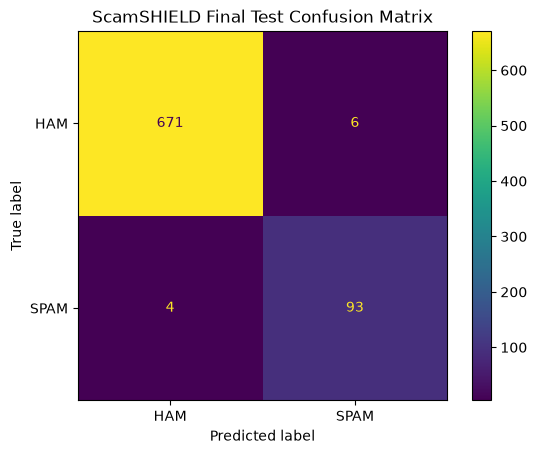

Confusion matrix:
[[671   6]
 [  4  93]]


In [16]:

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["HAM", "SPAM"]
)

disp.plot(values_format="d")
plt.title("ScamSHIELD Final Test Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)


save model

In [21]:

os.makedirs("models", exist_ok=True)

joblib.dump(final_tfidf, "models/tfidf_vectorizer.pkl")
joblib.dump(final_model, "models/scam_model.pkl")

print("Both files saved successfully!")
print("1. models/tfidf_vectorizer.pkl")
print("2. models/scam_model.pkl")


Both files saved successfully!
1. models/tfidf_vectorizer.pkl
2. models/scam_model.pkl


In [19]:

# from google.colab import files

# files.download("models/tfidf_vectorizer.pkl")
# files.download("models/scam_model.pkl")


 New SMS par prediction

In [20]:

def predict_message(message):
    cleaned_message = normalize_message(message)

    message_tfidf = final_tfidf.transform([cleaned_message])

    prediction = final_model.predict(message_tfidf)[0]

    probabilities = final_model.predict_proba(message_tfidf)[0]
    spam_index = list(final_model.classes_).index("spam")
    spam_probability = probabilities[spam_index] * 100

    if prediction == "spam":
        result = "SPAM"
    else:
        result = "NOT SPAM"

    return {
        "prediction": result,
        "spam_probability": round(spam_probability, 2),
        "message": message

    }


samples = [
    "Congratulations! You have won a free prize. Click now",
    "Hey, are we meeting tomorrow",
    "URGENT! Claim your cash reward now"
]

for message in samples:
    print(predict_message(message))


{'prediction': 'SPAM', 'spam_probability': np.float64(99.27), 'message': 'Congratulations! You have won a free prize. Click now'}
{'prediction': 'NOT SPAM', 'spam_probability': np.float64(2.79), 'message': 'Hey, are we meeting tomorrow'}
{'prediction': 'SPAM', 'spam_probability': np.float64(99.04), 'message': 'URGENT! Claim your cash reward now'}


In [22]:
import sys
import sklearn

print("Python executable:", sys.executable)
print("Notebook Scikit-learn:", sklearn.__version__)

Python executable: c:\Users\library.DESKTOP-OVD6QK9\AppData\Local\Programs\Python\Python314\python.exe
Notebook Scikit-learn: 1.9.1
